# AI-Powered Predictive Bed Demand Forecasting for Albion Care Network

### APPLICATION OF MACHINE LEARNING AND DEEP LEARNING MODELS

# Load Required Libraries

In [1]:
import sys
# Import Python warnings module
# Used to control warning messages displayed during execution
import warnings
# Ignore non-critical warning messages to keep notebook output clean
warnings.filterwarnings("ignore")
# Then import all your libraries
import pandas as pd  # For data manipulation and analysis
import numpy as np   # For numerical operations
# Import type hints to define expected data types in functions
# Improves readability and helps with debugging (no impact on runtime)
from typing import Dict, Any, List, Tuple

# Import data visualization libraries
import matplotlib.pyplot as plt  # For creating static visualizations
import matplotlib.dates as mdates
import seaborn as sns           # For enhanced statistical visualizations
import missingno as msno        # For visualisation of Missing Values
# Install holidays package if not installed
try:
    import holidays
except ImportError:
    print("Installing holidays package...")
    import sys
    !{sys.executable} -m pip install holidays
    import holidays
    import pickle
#==============================================================================
# Time Series Libraries
#==============================================================================

# Seasonal decomposition
from prophet import Prophet




# =============================================================================
# IMPORT MACHINE LEARNING LIBRARIES
# =============================================================================

# Import Random Forest Regression algorithm for predicting bed demand.

from sklearn.ensemble import RandomForestRegressor
# Import train_test_split to divide the dataset into training and testing sets.
# shuffle=False will later be used to preserve the time order for forecasting.
from sklearn.model_selection import train_test_split
# XGBoost algorithm
from xgboost import XGBRegressor
# Import evaluation metrics to measure model performance:
# LightGBM regression algorithm
from lightgbm import LGBMRegressor

# Import CatBoost package
import catboost


# Import CatBoost regression model
from catboost import CatBoostRegressor


# Import hyperparameter tuning and time-series validation tools

from sklearn.model_selection import (
    
    RandomizedSearchCV,
    
    TimeSeriesSplit

)

# TensorFlow deep learning libraries
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (

    # LSTM recurrent neural network layer
    LSTM,

    # Prevents overfitting
    Dropout,

    # Final prediction layer
    Dense
)

# Adam:
#     Adaptive optimisation algorithm used to update neural network weights.
#
# Learning rate controls how quickly the model learns.
from tensorflow.keras.optimizers import Adam
# Scaling features
from sklearn.preprocessing import MinMaxScaler
# Stops training when validation performance stops improving
from tensorflow.keras.callbacks import EarlyStopping
# Generates sequences dynamically without loading everything into memory
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

#
# EarlyStopping:
#     Stops training when validation performance stops improving.
#     Prevents overfitting and reduces training time.
#
# ReduceLROnPlateau:
#     Reduces learning rate when validation loss stops improving.
#     Helps the model converge to a better solution.
# L2 regularisation:
#     Penalises large model weights.
#     Reduces model complexity and improves generalisation.
from tensorflow.keras.regularizers import l2

#
# Keras Tuner:
#     Automatically searches for the best LSTM configuration.
#
# It optimises parameters such as:
#
# - Number of LSTM neurons
# - Dropout rate
# - Learning rate
#
import keras_tuner as kt

# =============================================================================
# HYPERPARAMETER OPTIMISATION
# =============================================================================
#

from tensorflow.keras.callbacks import (

    EarlyStopping,

    ReduceLROnPlateau

)

# RandomizedSearchCV automatically tests multiple combinations of parameters
# and identifies the best performing Random Forest configuration.

from sklearn.model_selection import RandomizedSearchCV

#========================================================================
# Packaged for Model Evaluation
#=======================================================================
# MAE  : Average absolute prediction error.
# RMSE : Penalises large forecasting errors.
# MAPE : Measures prediction error as a percentage.
# R2   : Measures how well the model explains variation in bed demand.

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Load Preprocessed Data

In [2]:
# Load bed demand data from pickle file into a pandas DataFrame
df = pd.read_pickle("preprocessed_data_FIXED.pkl")

In [3]:
df["datetime"] = pd.to_datetime(
    df[
        [
            "year",
            "month",
            "day",
            "hour"
        ]
    ]
)

In [4]:
# Preview the dataset to verify preprocessing and feature engineering.
df.head()

,ward,total_beds,occupied_beds,closed_beds,planned_staff,actual_staff,safe_ratio_met,ed_arrivals,surgeries_scheduled,hospital_name,...,month_name,quarter,year,is_holiday,season,occupancy_rate,staffing_ratio,available_beds,bed_pressure,datetime
0,0,38.0,160.0,0.0,18.0,18.0,1.00,225.0,0.0,2,...,4,1,2024,0,3,410.256410,0.947368,-122.0,4.102564,2024-01-01
1,6,11.0,33.0,0.0,5.0,4.0,0.75,80.0,0.0,0,...,4,1,2024,0,3,275.000000,0.666667,-22.0,2.750000,2024-01-01
2,4,18.0,57.0,0.0,24.0,24.0,1.00,225.0,0.0,2,...,4,1,2024,0,3,300.000000,0.960000,-39.0,3.000000,2024-01-01
3,5,20.0,13.0,0.0,10.0,10.0,1.00,140.0,0.0,3,...,4,1,2024,0,3,61.904762,0.909091,7.0,0.619048,2024-01-01
4,5,13.0,4.0,0.0,6.0,6.0,1.00,70.0,0.0,1,...,4,1,2024,0,3,28.571429,0.857143,9.0,0.285714,2024-01-01


In [4]:
# Show the number of rows and columns in the dataset.
df.shape

(27277, 40)

In [6]:
# Show the data types, non-missing values, and memory usage of the dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27277 entries, 0 to 27276
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ward                   27277 non-null  int32         
 1   total_beds             27277 non-null  float64       
 2   occupied_beds          27277 non-null  float64       
 3   closed_beds            27277 non-null  float64       
 4   planned_staff          27277 non-null  float64       
 5   actual_staff           27277 non-null  float64       
 6   safe_ratio_met         27277 non-null  float64       
 7   ed_arrivals            27277 non-null  float64       
 8   surgeries_scheduled    27277 non-null  float64       
 9   hospital_name          27277 non-null  int32         
 10  city                   27277 non-null  int32         
 11  tier                   27277 non-null  int32         
 12  specialty_emphasis     27277 non-null  int32         
 13  t

# Check for Multi-Collinearity

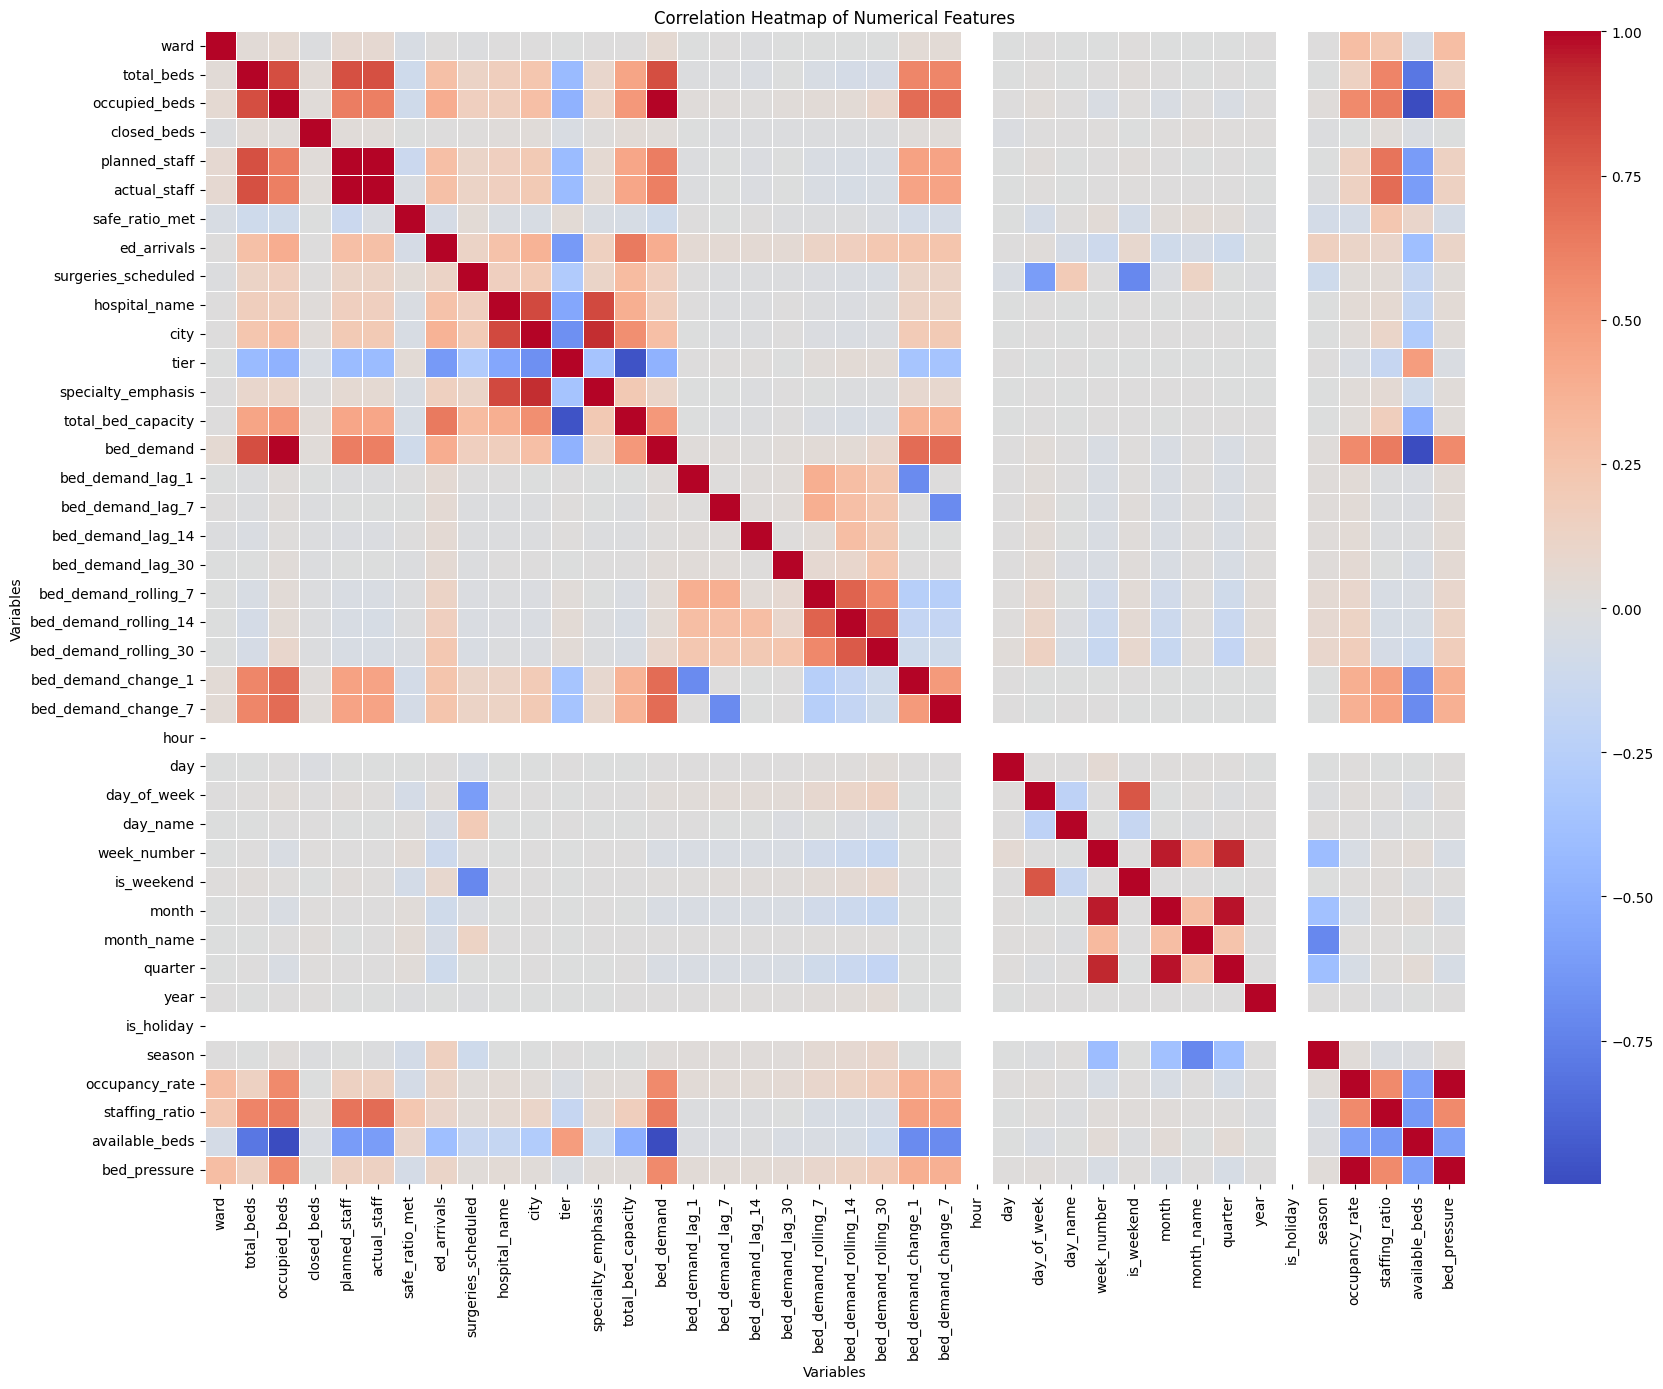

HIGHLY CORRELATED VARIABLES (>|0.80|)
             Feature_1           Feature_2  Correlation
2           total_beds       occupied_beds     0.818530
3           total_beds       planned_staff     0.809336
4           total_beds        actual_staff     0.805818
5           total_beds          bed_demand     0.818530
6        occupied_beds          total_beds     0.818530
8        occupied_beds          bed_demand     1.000000
9        occupied_beds      available_beds    -0.999382
11       planned_staff          total_beds     0.809336
13       planned_staff        actual_staff     0.994399
14        actual_staff          total_beds     0.805818
15        actual_staff       planned_staff     0.994399
21       hospital_name                city     0.828427
22       hospital_name  specialty_emphasis     0.829521
23                city       hospital_name     0.828427
25                city  specialty_emphasis     0.920514
27                tier  total_bed_capacity    -0.963992
28  specia

In [4]:
# =============================================================================
# CORRELATION HEATMAP FOR NUMERICAL VARIABLES
# =============================================================================
# Purpose:
# --------
# Analyse relationships between numerical variables to identify:
#
# - Multicollinearity between predictor variables.
# - Duplicate or highly related features.
# - Variables that may need removal before modelling.
#
# Correlation values:
#
# +1  = Strong positive relationship
#  0  = No linear relationship
# -1  = Strong negative relationship
#
# A correlation value above 0.80 or below -0.80 may indicate
# potential multicollinearity.
# =============================================================================


# =============================================================================
# IMPORT REQUIRED LIBRARIES
# =============================================================================

# =============================================================================
# STEP 1: SELECT NUMERICAL VARIABLES
# =============================================================================
# Automatically identify numerical columns including:
#
# - Integer variables
# - Floating-point variables
#
# These variables are suitable for correlation analysis.

numerical_features = df.select_dtypes(

    include=["int32", "int64", "float64"]

).columns.tolist()



# =============================================================================
# STEP 2: CREATE CORRELATION MATRIX
# =============================================================================
# Calculate Pearson correlation coefficients between all numerical variables.
#
# The correlation matrix shows how strongly variables move together.

correlation_matrix = df[numerical_features].corr()



# =============================================================================
# STEP 3: PLOT CORRELATION HEATMAP
# =============================================================================
# Visualise correlation values using colour intensity.
#
# Darker colours indicate stronger relationships between variables.

plt.figure(figsize=(18,14))


sns.heatmap(

    correlation_matrix,

    cmap="coolwarm",

    center=0,

    linewidths=0.5,

    annot=False

)


plt.title(

    "Correlation Heatmap of Numerical Features"

)


plt.xlabel(

    "Variables"

)


plt.ylabel(

    "Variables"

)


plt.tight_layout()


plt.show()



# =============================================================================
# STEP 4: IDENTIFY HIGHLY CORRELATED VARIABLES
# =============================================================================
# Extract feature pairs with correlation values greater than 0.80
# or less than -0.80.
#
# These variables should be reviewed because they may contain similar
# information.

high_correlation = (

    correlation_matrix

    .where(

        abs(correlation_matrix) > 0.80

    )

    .stack()

    .reset_index()

)



# Rename columns for easier interpretation

high_correlation.columns = [

    "Feature_1",

    "Feature_2",

    "Correlation"

]



# =============================================================================
# STEP 5: REMOVE SELF-CORRELATIONS
# =============================================================================
# Remove cases where a variable is compared with itself
# (correlation = 1).

high_correlation = high_correlation[

    high_correlation["Feature_1"] != high_correlation["Feature_2"]

]



# =============================================================================
# STEP 6: DISPLAY HIGHLY CORRELATED VARIABLES
# =============================================================================
# Review these variables before model training.
#
# Highly correlated features may be removed to:
#
# - Reduce redundancy.
# - Improve model interpretability.
# - Simplify SHAP explanations.

print("=" * 80)

print("HIGHLY CORRELATED VARIABLES (>|0.80|)")

print("=" * 80)


print(high_correlation)

### Remove Highly Correlated Variables

In [5]:
# =============================================================================
# REMOVE HIGHLY CORRELATED FEATURES
# =============================================================================
# Purpose:
# --------
# Remove redundant variables identified during correlation analysis.
#
# Benefits:
# - Reduces multicollinearity.
# - Prevents duplicate information entering the model.
# - Improves model efficiency.
# - Improves feature importance interpretation.
# - Improves SHAP explainability.
#
# Note:
# Tree-based models can handle correlated variables, but removing highly
# redundant features improves interpretability and reduces unnecessary noise.
# =============================================================================

features_to_remove =[

    # Target leakage
    "occupied_beds",
    "available_beds",
    "occupancy_rate",
    "bed_pressure",

    # Duplicate staffing
    "planned_staff",
    "staffed_beds",

    # Duplicate hospital information
    "city",
    "specialty_emphasis",

    # Duplicate hospital classification
    "tier",

    # Duplicate calendar variables
    "week_number",
    "quarter",
    "day_name",
    "month_name",

    # Redundant lag variables
    "bed_demand_lag_14",
    "bed_demand_lag_30",

    # Redundant rolling variables
    "bed_demand_rolling_14",
    "bed_demand_rolling_30",

    # Longer-term change
    "bed_demand_change_7"

]


# Remove correlated features from dataset
df_model = df.drop(columns=features_to_remove, errors="ignore")


# Display remaining variables
print("Remaining Features:")
print(df_model.columns.tolist())


# Check new dataset dimensions
print("\nDataset Shape After Removing Correlated Features:")
print(df_model.shape)

Remaining Features:
['ward', 'total_beds', 'closed_beds', 'actual_staff', 'safe_ratio_met', 'ed_arrivals', 'surgeries_scheduled', 'hospital_name', 'total_bed_capacity', 'bed_demand', 'bed_demand_lag_1', 'bed_demand_lag_7', 'bed_demand_rolling_7', 'bed_demand_change_1', 'hour', 'day', 'day_of_week', 'is_weekend', 'month', 'year', 'is_holiday', 'season', 'staffing_ratio', 'datetime']

Dataset Shape After Removing Correlated Features:
(27277, 24)


In [6]:
# Check remaining correlations
corr_matrix = df_model.select_dtypes(include="number").corr()

# Display correlations above 0.8
high_corr = (
    corr_matrix
    .where(abs(corr_matrix) > 0.8)
    .stack()
    .reset_index()
)

high_corr.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

# Remove duplicate pairs
high_corr = high_corr[
    high_corr["Feature_1"] != high_corr["Feature_2"]
]

print(high_corr)

       Feature_1     Feature_2  Correlation
2     total_beds  actual_staff     0.805818
3     total_beds    bed_demand     0.818530
5   actual_staff    total_beds     0.805818
12    bed_demand    total_beds     0.818530


# Time Series Model - SARIMAX

=== PROPHET DATASET ===
   ward  total_beds  occupied_beds  closed_beds  planned_staff  actual_staff  \
0     0        38.0          160.0          0.0           18.0          18.0   
1     6        32.0           41.0          0.0           13.0          11.0   
2     2        21.0           13.0          0.0            8.0           8.0   
3     7        10.0           41.0          0.0            4.0           4.0   
4     1         4.0            5.0          0.0            1.0           1.0   

   safe_ratio_met  ed_arrivals  surgeries_scheduled  hospital_name  ...  year  \
0             1.0        225.0                  0.0              2  ...  2024   
1             0.5        140.0                  0.0              3  ...  2024   
2             1.0        140.0                  0.0              3  ...  2024   
3             1.0         70.0                  0.0              1  ...  2024   
4             1.0        225.0                  0.0              2  ...  2024   

   is_ho

08:44:43 - cmdstanpy - INFO - Chain [1] start processing
08:44:54 - cmdstanpy - INFO - Chain [1] done processing


=== MODEL TRAINED SUCCESSFULLY ===
=== PROPHET PERFORMANCE ===
RMSE : 98.669
MAE  : 73.577
MAPE : 18457.048%
R2   : 0.761
=== FORECAST DATASET ===
            Actual_Bed_Demand  Predicted_Bed_Demand  Lower_Bound  Upper_Bound  \
datetime                                                                        
2025-08-08              383.0            449.656277   328.242059   570.634191   
2025-08-08              349.0            503.371851   380.261998   616.290145   
2025-08-08              243.0            276.225814   161.345605   394.723825   
2025-08-08              238.0            245.926277   128.773621   364.069706   
2025-08-08              179.0            173.180068    53.599732   294.649240   

              Residual  
datetime                
2025-08-08  -66.656277  
2025-08-08 -154.371851  
2025-08-08  -33.225814  
2025-08-08   -7.926277  
2025-08-08    5.819932  


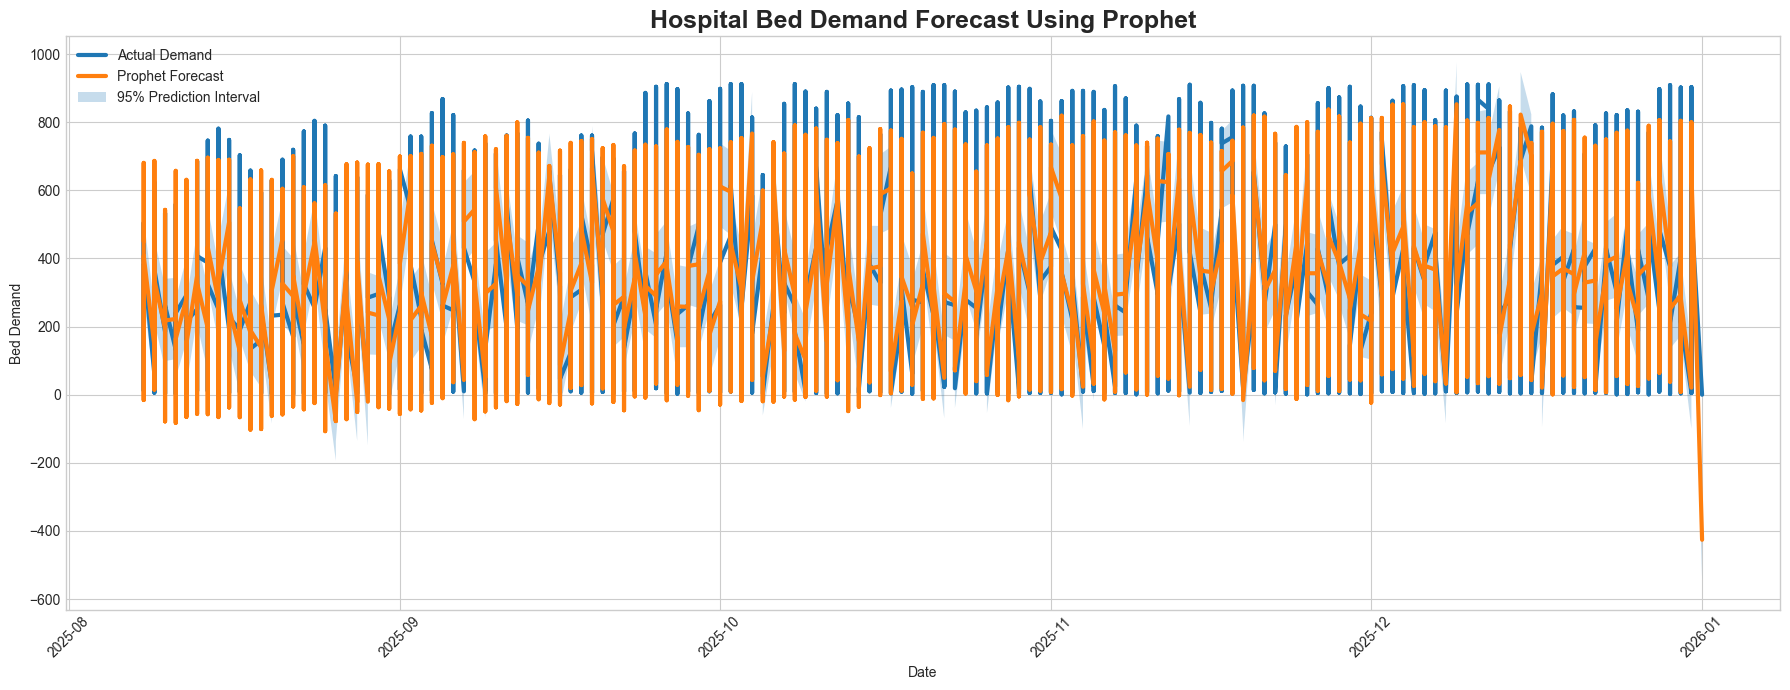

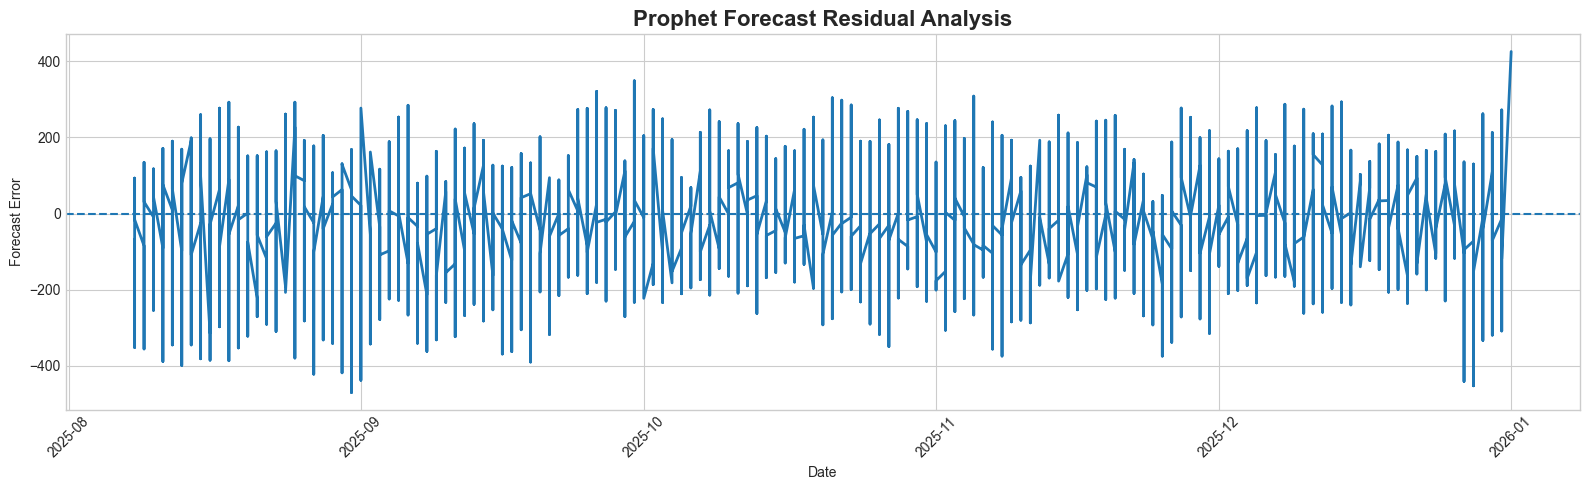

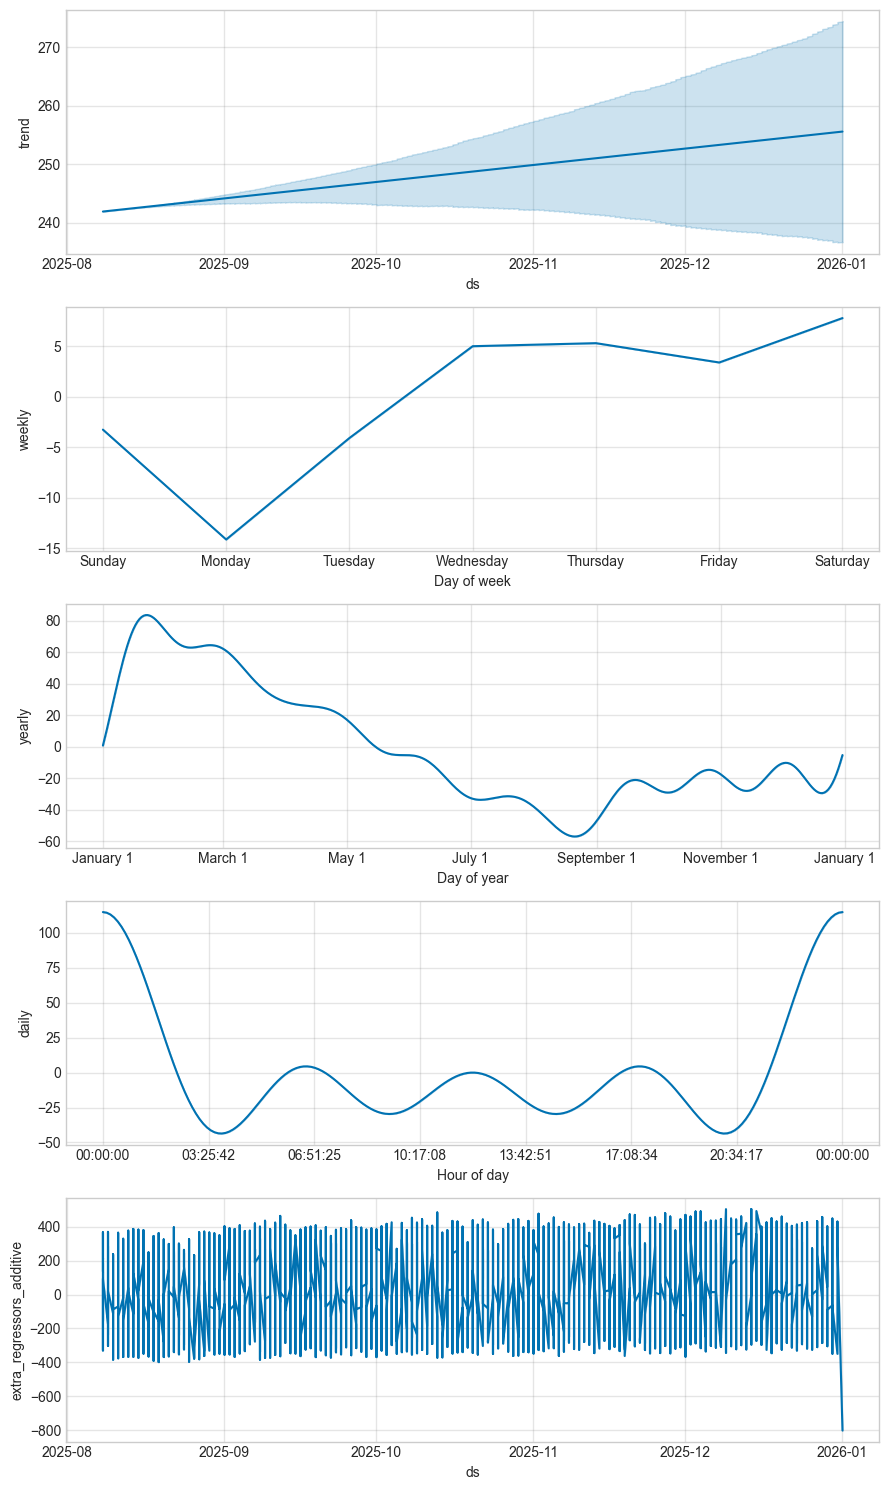

=== CSV FILES SAVED ===


NameError: name 'pickle' is not defined

In [7]:
# =============================================================================
# PROPHET REGRESSION PIPELINE
# HOSPITAL BED DEMAND FORECASTING
# =============================================================================
#
# Objective:
# ----------
# Build a Prophet regression forecasting model to predict hospital bed demand.
#
# Prophet combines:
#
# 1. Historical demand trend
# 2. Daily, weekly and yearly seasonality
# 3. Trend changepoints
# 4. External hospital operational drivers
#
# External regressors:
#
# - Capacity availability
# - Staffing pressure
# - Emergency demand
# - Surgical activity
# - Calendar effects
#
# ============================================================================

# =============================================================================
# 2. DEFINE TARGET VARIABLE AND EXTERNAL FEATURES
# =============================================================================
#
# Prophet requires:
#
# ds:
#     datetime variable
#
# y:
#     forecasting target
#
# External regressors help Prophet understand hospital operations.
#
# =============================================================================


prophet_target = "bed_demand"


prophet_exog_features = [

    # -------------------------
    # Capacity variables
    # -------------------------

    "total_beds",
    "closed_beds",


    # -------------------------
    # Staffing variables
    # -------------------------

    "actual_staff",
    "staffing_ratio",


    # -------------------------
    # Demand pressure variables
    # -------------------------

    "ed_arrivals",
    "surgeries_scheduled",


    # -------------------------
    # Calendar variables
    # -------------------------

    "hour",
    "day_of_week",
    "is_weekend",
    "is_holiday",
    "month"

]



# =============================================================================
# 3. CREATE PROPHET DATASET
# =============================================================================
#
# Prophet requires:
#
# ds = datetime column
# y  = target variable
#
# =============================================================================


prophet_df = df.copy()



# Convert datetime into Prophet format

prophet_df["ds"] = pd.to_datetime(

    prophet_df["datetime"]

)



# Assign target variable

prophet_df["y"] = prophet_df[prophet_target]



# Sort chronologically

prophet_df = prophet_df.sort_values(

    "ds"

)



prophet_df = prophet_df.reset_index(

    drop=True

)



print("=== PROPHET DATASET ===")

print(prophet_df.head())

print(prophet_df.shape)



# =============================================================================
# 4. DATA QUALITY CHECK
# =============================================================================
#
# Remove missing target observations.
#
# Prophet cannot train without target values.
#
# =============================================================================


print("=== MISSING VALUES ===")

print(prophet_df.isnull().sum())



prophet_df = prophet_df.dropna(

    subset=["y"]

)



# =============================================================================
# 5. TRAIN TEST SPLIT
# =============================================================================
#
# Time series forecasting requires chronological splitting.
#
# Training:
#     Past observations
#
# Testing:
#     Future unseen observations
#
# =============================================================================


split_index = int(

    len(prophet_df) * 0.80

)



train_df = prophet_df.iloc[:split_index]

test_df = prophet_df.iloc[split_index:]



print("=== TRAIN TEST SIZE ===")

print("Train:", train_df.shape)

print("Test :", test_df.shape)



# =============================================================================
# 6. BUILD PROPHET MODEL
# =============================================================================
#
# yearly_seasonality:
#     Annual hospital demand patterns
#
# weekly_seasonality:
#     Weekday/weekend variation
#
# daily_seasonality:
#     Hourly demand cycles
#
# changepoint_prior_scale:
#     Controls flexibility of trend changes
#
# =============================================================================


prophet_model = Prophet(

    yearly_seasonality=True,

    weekly_seasonality=True,

    daily_seasonality=True,

    changepoint_prior_scale=0.05

)



# =============================================================================
# 7. ADD EXTERNAL REGRESSORS
# =============================================================================
#
# Prophet learns relationships between demand and operational drivers.
#
# Example:
#
# Increased ED arrivals
#          ↓
# Increased bed demand
#
# =============================================================================


for feature in prophet_exog_features:

    prophet_model.add_regressor(

        feature

    )



# =============================================================================
# 8. TRAIN PROPHET MODEL
# =============================================================================


prophet_model.fit(

    train_df[
        ["ds","y"] + prophet_exog_features
    ]

)



print("=== MODEL TRAINED SUCCESSFULLY ===")



# =============================================================================
# 9. GENERATE FORECAST
# =============================================================================
#
# Prophet requires future timestamps and future regressor values.
#
# =============================================================================


future = test_df[

    ["ds"] + prophet_exog_features

]



forecast = prophet_model.predict(

    future

)



# Point prediction

y_pred = forecast["yhat"].values



# Actual values

y_actual = test_df["y"].values



# =============================================================================
# 10. MODEL PERFORMANCE
# =============================================================================


rmse = np.sqrt(

    mean_squared_error(

        y_actual,

        y_pred

    )

)


mae = mean_absolute_error(

    y_actual,

    y_pred

)


mape = np.mean(
    np.abs(
        (y_actual - y_pred) /
        np.maximum(y_actual,1)
    )
) * 100



r2 = r2_score(

    y_actual,

    y_pred

)



print("=== PROPHET PERFORMANCE ===")

print(f"RMSE : {rmse:.3f}")

print(f"MAE  : {mae:.3f}")

print(f"MAPE : {mape:.3%}")

print(f"R2   : {r2:.3f}")



# =============================================================================
# 11. CREATE ENHANCED FORECAST DATASET
# =============================================================================
#
# IMPORTANT:
#
# This section creates all columns required later:
#
# - Actual demand
# - Forecast demand
# - Lower uncertainty interval
# - Upper uncertainty interval
# - Residual errors
#
# =============================================================================


forecast_df = pd.DataFrame({

    "datetime": test_df["ds"].values,


    "Actual_Bed_Demand": y_actual,


    "Predicted_Bed_Demand": y_pred,


    "Lower_Bound":

        forecast["yhat_lower"].values,


    "Upper_Bound":

        forecast["yhat_upper"].values,


    "Residual":

        y_actual - y_pred

})



forecast_df["datetime"] = pd.to_datetime(

    forecast_df["datetime"]

)



forecast_df = forecast_df.set_index(

    "datetime"

)



print("=== FORECAST DATASET ===")

print(forecast_df.head())



# =============================================================================
# 12. CREATE FORECAST HORIZONS
# =============================================================================
#
# Different operational decisions require different time scales.
#
# =============================================================================


hourly_forecast = forecast_df.copy()



daily_forecast = forecast_df.resample(

    "D"

).mean()



weekly_forecast = forecast_df.resample(

    "W"

).mean()



monthly_forecast = forecast_df.resample(

    "ME"

).mean()



holiday_forecast = test_df.loc[

    test_df["is_holiday"] == 1

].copy()



# =============================================================================
# 13. ATTRACTIVE FORECAST VISUALISATIONS
# =============================================================================


plt.style.use(

    "seaborn-v0_8-whitegrid"

)



# -----------------------------------------------------------------------------
# Actual vs Forecast with Confidence Interval
# -----------------------------------------------------------------------------


plt.figure(figsize=(18,7))


plt.plot(

    forecast_df.index,

    forecast_df["Actual_Bed_Demand"],

    linewidth=3,

    label="Actual Demand"

)


plt.plot(

    forecast_df.index,

    forecast_df["Predicted_Bed_Demand"],

    linewidth=3,

    label="Prophet Forecast"

)


plt.fill_between(

    forecast_df.index,

    forecast_df["Lower_Bound"],

    forecast_df["Upper_Bound"],

    alpha=0.25,

    label="95% Prediction Interval"

)



plt.title(

    "Hospital Bed Demand Forecast Using Prophet",

    fontsize=18,

    fontweight="bold"

)


plt.xlabel("Date")

plt.ylabel("Bed Demand")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()



# -----------------------------------------------------------------------------
# Residual Plot
# -----------------------------------------------------------------------------


plt.figure(figsize=(16,5))


plt.plot(

    forecast_df.index,

    forecast_df["Residual"],

    linewidth=2

)


plt.axhline(

    0,

    linestyle="--"

)


plt.title(

    "Prophet Forecast Residual Analysis",

    fontsize=16,

    fontweight="bold"

)


plt.xlabel("Date")

plt.ylabel("Forecast Error")


plt.xticks(rotation=45)

plt.tight_layout()

plt.show()



# =============================================================================
# 14. PROPHET COMPONENT ANALYSIS
# =============================================================================
#
# Shows:
#
# - Trend
# - Daily seasonality
# - Weekly seasonality
# - Yearly seasonality
#
# =============================================================================


prophet_model.plot_components(

    forecast

)


plt.show()



# =============================================================================
# 15. SAVE ALL FORECAST DATASETS AS CSV
# =============================================================================
#
# CSV outputs can be used by:
#
# - Power BI
# - Tableau
# - Hospital dashboards
# - Further ML model comparison
#
# =============================================================================


forecast_df.to_csv(

    "Prophet_All_Forecasts.csv"

)


hourly_forecast.to_csv(

    "Prophet_Hourly_Forecast.csv"

)


daily_forecast.to_csv(

    "Prophet_Daily_Forecast.csv"

)


weekly_forecast.to_csv(

    "Prophet_Weekly_Forecast.csv"

)


monthly_forecast.to_csv(

    "Prophet_Monthly_Forecast.csv"

)


holiday_forecast.to_csv(

    "Prophet_Holiday_Forecast.csv"

)



print("=== CSV FILES SAVED ===")



# =============================================================================
# 16. SAVE TRAINED MODEL
# =============================================================================


with open(

    "Prophet_Bed_Demand_Model.pkl",

    "wb"

) as file:

    pickle.dump(

        prophet_model,

        file

    )


print("=== PROPHET PIPELINE COMPLETED SUCCESSFULLY ===")



# Final Variables for ML Modelling

In [ ]:
# DEFINE FINAL FEATURES FOR HOSPITAL BED DEMAND FORECASTING
# =============================================================================
# Purpose:
# --------
# Define the variables retained for machine learning model training.
#
# The selected features represent:
#
# - Hospital characteristics
# - Bed capacity and availability
# - Staffing conditions
# - Patient flow indicators
# - Historical demand patterns
# - Time-based seasonal effects
#
# Note:
# -----
# 'bed_demand' is the target variable and should be removed from X
# before model training to prevent target leakage.
# =============================================================================


remaining_features = [

    # =========================================================================
    # Hospital characteristics
    # =========================================================================
    # Identifies hospital location/unit characteristics and differences
    # between facilities.

    'ward',

    'hospital_name',



    # =========================================================================
    # Bed capacity and availability variables
    # =========================================================================
    # Represents physical capacity and operational bed constraints.

    'total_beds',

    'closed_beds',

    'total_bed_capacity',



    # =========================================================================
    # Staffing and operational capacity variables
    # =========================================================================
    # Captures workforce availability and ability to accommodate patients.

    'actual_staff',

    'staffing_ratio',

    'safe_ratio_met',



    # =========================================================================
    # Patient flow and demand drivers
    # =========================================================================
    # Variables that influence future bed requirements.

    'ed_arrivals',

    'surgeries_scheduled',



    # =========================================================================
    # Target variable
    # =========================================================================
    # The variable to be predicted by the forecasting models.
    #
    # Remove this variable from predictor variables (X) during training.

    'bed_demand',



    # =========================================================================
    # Historical demand features
    # =========================================================================
    # Lag and rolling features capture previous demand patterns and
    # temporal dependencies.

    'bed_demand_lag_1',

    'bed_demand_lag_7',

    'bed_demand_rolling_7',

    'bed_demand_change_1',



    # =========================================================================
    # Time-based forecasting variables
    # =========================================================================
    # Capture daily, weekly, seasonal and holiday effects.

    'hour',

    'day',

    'day_of_week',

    'is_weekend',

    'month',

    'year',

    'is_holiday',

    'season'

]

# Base Machine Learning Modelling Using Random Forest

In [25]:
# =============================================================================
# RANDOM FOREST REGRESSOR PIPELINE FOR HOSPITAL BED DEMAND FORECASTING
# =============================================================================
# Purpose:
# --------
# This pipeline trains a Random Forest Regression model to predict hospital
# bed demand and identify the most influential forecasting variables.
#
# The pipeline performs:
#
# 1. Separates predictor variables (X) from the target variable.
# 2. Splits the data into training and testing sets while preserving
#    chronological order.
# 3. Trains a Random Forest Regressor.
# 4. Evaluates model performance.
# 5. Calculates feature importance scores.
# 6. Displays the Top 20 most important features.
# 7. Selects important variables for advanced forecasting models.
# =============================================================================


# =============================================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================================
# =============================================================================
# STEP 1: DEFINE INPUT FEATURES AND TARGET VARIABLE
# =============================================================================
# Remove the target variable from the predictors.

X = df[remaining_features].drop(

    columns=["bed_demand"]

)

y = df["bed_demand"]

# =============================================================================
# STEP 2: SPLIT DATA INTO TRAINING AND TESTING SETS
# =============================================================================
# shuffle=False preserves the chronological order of observations,
# which is essential for forecasting problems.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)


# =============================================================================
# STEP 3: INITIALISE RANDOM FOREST MODEL
# =============================================================================
# n_estimators:
# Number of decision trees.
#
# random_state:
# Ensures reproducibility.
#
# n_jobs=-1:
# Uses all CPU cores.

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


# =============================================================================
# STEP 4: TRAIN MODEL
# =============================================================================

rf_model.fit(X_train, y_train)


# =============================================================================
# STEP 5: MAKE PREDICTIONS
# =============================================================================

y_pred = rf_model.predict(X_test)


# =============================================================================
# STEP 6: EVALUATE MODEL PERFORMANCE
# =============================================================================

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mae = mean_absolute_error(y_test, y_pred)

mape = np.mean(
    np.abs(
        (y_actual - y_pred) /
        np.maximum(y_actual,1)
    )
) * 100


r2 = r2_score(y_test, y_pred)


print("=" * 80)
print("RANDOM FOREST MODEL PERFORMANCE")
print("=" * 80)

print(f"RMSE : {rmse:.3f}")
print(f"MAE  : {mae:.3f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")


# =============================================================================
# STEP 7: COMPUTE FEATURE IMPORTANCE
# =============================================================================
# Random Forest estimates the contribution of every predictor
# to reducing prediction error.

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": rf_model.feature_importances_

})


# Rank variables by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


# =============================================================================
# STEP 8: DISPLAY TOP 20 IMPORTANT FEATURES
# =============================================================================
# The most influential variables for predicting hospital bed demand.

top20_features = feature_importance.head(15)

print("=" * 80)
print("TOP 20 MOST IMPORTANT FEATURES")
print("=" * 80)

print(top20_features)


# =============================================================================
# STEP 9: SELECT IMPORTANT FEATURES
# =============================================================================
# Keep only variables above the selected importance threshold.

importance_threshold = 0.01

selected_features = feature_importance[
    feature_importance["Importance"] >= importance_threshold
]["Feature"].tolist()


print("=" * 80)
print("SELECTED FEATURES")
print("=" * 80)

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print()
print(f"Number of Selected Features: {len(selected_features)}")


# =============================================================================
# STEP 10: CREATE FEATURE-SELECTED DATASET
# =============================================================================
# Create a reduced dataset using only the selected variables.

X_selected = df[selected_features]

y_selected = df["bed_demand"]


print("=" * 80)
print("FEATURE-SELECTED DATASET")
print("=" * 80)

print(f"Predictor Shape : {X_selected.shape}")
print(f"Target Shape    : {y_selected.shape}")


# =============================================================================
# STEP 11: SAVE TOP 20 FEATURES (OPTIONAL)
# =============================================================================
# Save the ranked Top 20 important features for reporting or dissertation.

top20_features.to_csv(
    "top_20_random_forest_features.csv",
    index=False
)

print("=" * 80)
print("Top 20 Feature Importance Saved Successfully")
print("=" * 80)


# =============================================================================
# END OF RANDOM FOREST FEATURE SELECTION PIPELINE
# =============================================================================

RANDOM FOREST MODEL PERFORMANCE
RMSE : 18.112
MAE  : 10.762
MAPE : 501.79%
R²   : 0.992
TOP 20 MOST IMPORTANT FEATURES
                 Feature  Importance
0             total_beds    0.754078
1    bed_demand_change_1    0.128516
2       bed_demand_lag_1    0.082168
3          hospital_name    0.007906
4     total_bed_capacity    0.007412
5                  month    0.004079
6   bed_demand_rolling_7    0.003159
7                   ward    0.002707
8           actual_staff    0.002111
9            ed_arrivals    0.001700
10        staffing_ratio    0.001534
11                   day    0.001232
12                season    0.001052
13      bed_demand_lag_7    0.000969
14   surgeries_scheduled    0.000585
SELECTED FEATURES
1. total_beds
2. bed_demand_change_1
3. bed_demand_lag_1

Number of Selected Features: 3
FEATURE-SELECTED DATASET
Predictor Shape : (27277, 3)
Target Shape    : (27277,)
Top 20 Feature Importance Saved Successfully


In [29]:
# =============================================================================
# RANDOM FOREST HYPERPARAMETER TUNING PIPELINE FOR BED DEMAND FORECASTING
# =============================================================================
# Purpose:
# --------
# This pipeline optimises the Random Forest Regressor by testing different
# combinations of model parameters.
#
# The objective is to:
#
# - Reduce overfitting.
# - Improve forecasting accuracy.
# - Improve model generalisation on unseen hospital data.
# - Produce more reliable feature importance rankings.
#
# The tuning process evaluates:
#
# 1. Number of trees (n_estimators)
# 2. Maximum tree depth (max_depth)
# 3. Minimum samples required for splitting (min_samples_split)
# 4. Minimum samples per leaf node (min_samples_leaf)
# 5. Number of features used at each split (max_features)
# 6. Bootstrap sampling strategy
#
# =============================================================================


# =============================================================================
# STEP 1: CREATE BASE RANDOM FOREST MODEL
# =============================================================================
# This is the initial model that will be optimised.
#
# random_state:
# Ensures reproducible results.
#
# n_jobs=-1:
# Uses all available CPU cores to speed up training.
#
# =============================================================================

rf = RandomForestRegressor(

    random_state=42,

    n_jobs=-1

)



# =============================================================================
# STEP 2: DEFINE HYPERPARAMETER SEARCH SPACE
# =============================================================================
# These parameters control the complexity and learning behaviour
# of the Random Forest model.
#
# More complex models:
# - Capture more patterns.
# - Risk overfitting.
#
# Simpler models:
# - Generalise better.
# - May miss important relationships.
#
# =============================================================================

param_grid = {


    # Number of decision trees in the forest.
    # Increasing trees improves stability but increases computation.

    "n_estimators": [

        100,
        200,
        300,
        500

    ],



    # Maximum depth of each decision tree.
    # Limiting depth reduces overfitting.

    "max_depth": [

        5,
        10,
        15,
        20,
        None

    ],



    # Minimum number of observations required to split a node.
    # Higher values create simpler trees.

    "min_samples_split": [

        2,
        5,
        10,
        20

    ],



    # Minimum number of observations allowed in a leaf node.
    # Increasing this value smooths predictions.

    "min_samples_leaf": [

        1,
        2,
        5,
        10

    ],



    # Number of variables considered when creating each split.
    # Lower values reduce correlation between trees.

    "max_features": [

        "sqrt",
        "log2",
        0.5,
        0.8

    ],



    # Whether bootstrap samples are used when building trees.

    "bootstrap": [

        True,
        False

    ]

}



# =============================================================================
# STEP 3: INITIALISE RANDOM SEARCH CROSS VALIDATION
# =============================================================================
# RandomizedSearchCV evaluates random combinations of parameters.
#
# It is preferred over GridSearchCV because the dataset is large and
# testing every possible combination would be computationally expensive.
#
# Parameters:
#
# n_iter:
# Number of parameter combinations tested.
#
# cv:
# Number of cross-validation folds.
#
# scoring:
# Negative RMSE is used because lower RMSE represents better performance.
#
# =============================================================================

rf_search = RandomizedSearchCV(

    estimator=rf,

    param_distributions=param_grid,

    n_iter=30,

    scoring="neg_root_mean_squared_error",

    cv=3,

    random_state=42,

    n_jobs=-1,

    verbose=2

)



# =============================================================================
# STEP 4: TRAIN RANDOM SEARCH MODEL
# =============================================================================
# The algorithm trains multiple Random Forest models using different
# parameter combinations and identifies the best configuration.

rf_search.fit(

    X_train,

    y_train

)



# =============================================================================
# STEP 5: DISPLAY BEST MODEL PARAMETERS
# =============================================================================
# These are the optimal parameters selected based on RMSE performance.

print("=" * 80)

print("BEST RANDOM FOREST PARAMETERS")

print("=" * 80)

print(rf_search.best_params_)



# =============================================================================
# STEP 6: CREATE FINAL OPTIMISED RANDOM FOREST MODEL
# =============================================================================
# Extract the Random Forest model with the best hyperparameter combination.

best_rf_model = rf_search.best_estimator_



# =============================================================================
# STEP 8: EVALUATE OPTIMISED RANDOM FOREST MODEL PERFORMANCE
# =============================================================================
#
# Evaluation metrics:
#
# RMSE:
# Measures the average magnitude of prediction errors.
# Lower values indicate better forecasting accuracy.
#
# MAE:
# Measures average absolute difference between actual
# and predicted bed demand.
#
# MAPE:
# Measures forecasting error as a percentage.
#
# R²:
# Measures how much variation in bed demand is explained
# by the Random Forest model.
#
# =============================================================================


# Root Mean Squared Error

rmse_tuned = np.sqrt(

    mean_squared_error(

        y_test,

        y_pred_tuned

    )

)



# Mean Absolute Error

mae_tuned = mean_absolute_error(

    y_test,

    y_pred_tuned

)



# Mean Absolute Percentage Error
#
# Avoid division by zero by replacing zero demand values
# with 1.

mape_tuned = np.mean(

    np.abs(

        (y_test - y_pred_tuned) /

        np.maximum(y_test,1)

    )

) * 100



# R-squared

r2_tuned = r2_score(

    y_test,

    y_pred_tuned

)

print("=" * 80)

print("OPTIMISED RANDOM FOREST PERFORMANCE")

print("=" * 80)


print(f"RMSE : {rmse_tuned:.3f}")

print(f"MAE  : {mae_tuned:.3f}")

print(f"MAPE : {mape_tuned:.2f}%")

print(f"R²   : {r2_tuned:.3f}")



# =============================================================================
# STEP 9: CALCULATE FEATURE IMPORTANCE
# =============================================================================
# Random Forest calculates the contribution of each variable
# in reducing prediction error.
#
# Higher importance means the variable contributes more
# to predicting hospital bed demand.

tuned_feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": best_rf_model.feature_importances_

})



# Sort features from most important to least important.

tuned_feature_importance = tuned_feature_importance.sort_values(

    by="Importance",

    ascending=False

).reset_index(drop=True)



print("=" * 80)

print("TOP FEATURES AFTER MODEL TUNING")

print("=" * 80)


print(

    tuned_feature_importance.head(15)

)



# =============================================================================
# STEP 10: SAVE OPTIMISED RANDOM FOREST MODEL
# =============================================================================
# Saving the model allows future prediction without retraining.


with open(

    "optimised_random_forest_bed_demand.pkl",

    "wb"

) as file:

    pickle.dump(

        best_rf_model,

        file

    )



print("=" * 80)

print("OPTIMISED RANDOM FOREST MODEL SAVED SUCCESSFULLY")

print("=" * 80)



# =============================================================================
# RANDOM FOREST OPTIMISATION PIPELINE COMPLETE
# =============================================================================
# The optimised model is now ready for:
#
# - Hospital bed demand forecasting
# - Feature importance analysis
# - SHAP explainability
# - Benchmark comparison with:
#       XGBoost
#       LightGBM
#       CatBoost
#       SARIMAX
#       LSTM
#
# =============================================================================

Fitting 3 folds for each of 30 candidates, totalling 90 fits
BEST RANDOM FOREST PARAMETERS
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': 15, 'bootstrap': False}
OPTIMISED RANDOM FOREST PERFORMANCE
RMSE : 21.602
MAE  : 12.989
MAPE : 18.62%
R²   : 0.989
TOP FEATURES AFTER MODEL TUNING
                 Feature  Importance
0             total_beds    0.629645
1    bed_demand_change_1    0.135083
2           actual_staff    0.093198
3       bed_demand_lag_1    0.074759
4         staffing_ratio    0.020640
5     total_bed_capacity    0.012983
6                   ward    0.011217
7          hospital_name    0.008492
8                  month    0.004739
9            ed_arrivals    0.002703
10  bed_demand_rolling_7    0.002521
11                season    0.001812
12                   day    0.000973
13      bed_demand_lag_7    0.000441
14   surgeries_scheduled    0.000365
OPTIMISED RANDOM FOREST MODEL SAVED SUCCESSFULLY


## Train Advanced ML Models - XGBOOST Regressor

In [8]:
# =============================================================================
# XGBOOST REGRESSOR PIPELINE
# HOSPITAL BED DEMAND FORECASTING
# =============================================================================
#
# Objective:
# ----------
# Train an XGBoost regression model to forecast hospital bed demand.
#
# Improvements included:
#
# ✓ Remove datetime object causing XGBoost error
# ✓ Extract useful time-based forecasting features
# ✓ Maintain chronological train-test split
# ✓ Prevent data leakage
# ✓ Evaluate forecasting accuracy
#
# =============================================================================



# =============================================================================
# 1. COPY MODEL DATASET
# =============================================================================

xgb_df = df_model.copy()



# =============================================================================
# 2. FEATURE ENGINEERING FROM DATETIME
# =============================================================================
#
# XGBoost cannot process datetime64 variables directly.
#
# Therefore, datetime is converted into numerical forecasting features.
#
# These features help the model learn:
#
# - Hourly demand patterns
# - Weekday effects
# - Seasonal demand changes
# - Long-term trends
#
# =============================================================================


if "datetime" in xgb_df.columns:


    # Convert datetime format

    xgb_df["datetime"] = pd.to_datetime(

        xgb_df["datetime"]

    )


    # Extract time features

    xgb_df["year"] = xgb_df["datetime"].dt.year

    xgb_df["month"] = xgb_df["datetime"].dt.month

    xgb_df["day"] = xgb_df["datetime"].dt.day

    xgb_df["hour"] = xgb_df["datetime"].dt.hour

    xgb_df["day_of_week"] = xgb_df["datetime"].dt.dayofweek

    xgb_df["week_number"] = xgb_df["datetime"].dt.isocalendar().week.astype(int)



    # Weekend indicator

    xgb_df["is_weekend"] = (

        xgb_df["day_of_week"] >= 5

    ).astype(int)



    # Remove original datetime column

    xgb_df.drop(

        columns=["datetime"],

        inplace=True

    )



# =============================================================================
# 3. DEFINE TARGET AND FEATURES
# =============================================================================


target = "bed_demand"



# Predictor variables

X = xgb_df.drop(

    columns=[target]

)



# Target variable

y = xgb_df[target]



print("="*80)

print("FEATURE DATASET")

print("="*80)


print(X.head())

print(X.shape)



# =============================================================================
# 4. CHRONOLOGICAL TRAIN TEST SPLIT
# =============================================================================
#
# Random splitting is avoided because this is a forecasting problem.
#
# Training:
# Historical hospital data
#
# Testing:
# Future unseen observations
#
# =============================================================================


split_index = int(

    len(X) * 0.80

)



X_train = X.iloc[:split_index]


X_test = X.iloc[split_index:]



y_train = y.iloc[:split_index]


y_test = y.iloc[split_index:]



print("="*80)

print("TRAIN TEST SPLIT")

print("="*80)


print("Training:", X_train.shape)

print("Testing :", X_test.shape)



# =============================================================================
# 5. INITIALISE XGBOOST MODEL
# =============================================================================
#
# Regularisation parameters are included to reduce overfitting.
#
# =============================================================================


xgb_model = XGBRegressor(

    n_estimators=500,

    learning_rate=0.05,

    max_depth=6,

    min_child_weight=5,

    subsample=0.8,

    colsample_bytree=0.8,

    reg_alpha=0.1,

    reg_lambda=1,

    objective="reg:squarederror",

    random_state=42,

    n_jobs=-1

)



# =============================================================================
# 6. TRAIN MODEL
# =============================================================================


xgb_model.fit(

    X_train,

    y_train

)



print("="*80)

print("XGBOOST MODEL TRAINED")

print("="*80)



# =============================================================================
# 7. GENERATE FORECASTS
# =============================================================================


y_pred = xgb_model.predict(

    X_test

)



# =============================================================================
# 8. MODEL PERFORMANCE EVALUATION
# =============================================================================


mae = mean_absolute_error(

    y_test,

    y_pred

)



rmse = np.sqrt(

    mean_squared_error(

        y_test,

        y_pred

    )

)



# Correct MAPE calculation

mape = np.mean(

    np.abs(

        (y_test.values - y_pred)

        /

        np.maximum(y_test.values,1)

    )

) * 100



r2 = r2_score(

    y_test,

    y_pred

)



print("="*80)

print("XGBOOST PERFORMANCE")

print("="*80)


print(

f"MAE  : {mae:.3f}"

)


print(

f"RMSE : {rmse:.3f}"

)


print(

f"MAPE : {mape:.2f}%"

)


print(

f"R²   : {r2:.3f}"

)



# =============================================================================
# 9. FEATURE IMPORTANCE
# =============================================================================
#
# Shows which variables contribute most to predicting bed demand.
#
# =============================================================================


feature_importance = pd.DataFrame(

    {

        "Feature":X.columns,

        "Importance":xgb_model.feature_importances_

    }

)



feature_importance = feature_importance.sort_values(

    by="Importance",

    ascending=False

)



print("="*80)

print("TOP XGBOOST FEATURES")

print("="*80)


print(

feature_importance.head(15)

)



# =============================================================================
# 10. SAVE MODEL
# =============================================================================


import pickle


with open(

    "xgboost_bed_demand_forecasting.pkl",

    "wb"

) as file:


    pickle.dump(

        xgb_model,

        file

    )



print("="*80)

print("XGBOOST MODEL SAVED SUCCESSFULLY")

print("="*80)

FEATURE DATASET
   ward  total_beds  closed_beds  actual_staff  safe_ratio_met  ed_arrivals  \
0     0        38.0          0.0          18.0            1.00        225.0   
1     6        11.0          0.0           4.0            0.75         80.0   
2     4        18.0          0.0          24.0            1.00        225.0   
3     5        20.0          0.0          10.0            1.00        140.0   
4     5        13.0          0.0           6.0            1.00         70.0   

   surgeries_scheduled  hospital_name  total_bed_capacity  bed_demand_lag_1  \
0                  0.0              2                 224               0.0   
1                  0.0              0                 126             160.0   
2                  0.0              2                 224              33.0   
3                  0.0              3                 164              57.0   
4                  0.0              1                  94              13.0   

   ...  hour  day  day_of_week  is

In [13]:
# =============================================================================
# XGBOOST HOSPITAL BED DEMAND FORECASTING - DASHBOARD DATA PIPELINE
# =============================================================================
#
# PURPOSE:
# --------
# Prepare XGBoost forecast results for Streamlit dashboard deployment.
#
# This pipeline:
#
# 1. Generates predictions from the trained XGBoost model.
# 2. Combines actual and predicted bed demand.
# 3. Calculates forecast errors.
# 4. Adds hourly, daily, weekly, monthly and seasonal time dimensions.
# 5. Creates dashboard-ready datasets.
# 6. Saves forecasting outputs.
#
# =============================================================================





# =============================================================================
# STEP 1: CREATE TEST FORECAST DATASET
# =============================================================================
#
# Use the same X_test dataset used during model evaluation.
#
# X_test contains only predictor variables.
# y_test contains actual observed bed demand.
#
# =============================================================================


forecast_df = X_test.copy()



# =============================================================================
# STEP 2: GENERATE XGBOOST FORECASTS
# =============================================================================
#
# Use the trained XGBoost model to predict future bed demand.
#
# =============================================================================


forecast_df["predicted_bed_demand"] = (
    xgb_model.predict(X_test)
)



# Add actual demand values

forecast_df["actual_bed_demand"] = (
    y_test.values
)


# =============================================================================
# STEP 3A: RESTORE OCCUPANCY RATE
# =============================================================================
#
# PURPOSE:
# --------
# Restore the occupancy rate from the original modelling dataset.
#
# Although occupancy_rate is used as an input feature during model training,
# it is also valuable for dashboard visualisation because it shows how much
# of the hospital bed capacity is occupied during each forecast period.
#
# Occupancy Rate (%) =
#
#        Occupied Beds
# ----------------------------- × 100
#        Total Bed Capacity
#
# Business Use:
#
# • Monitor hospital utilisation
# • Identify periods approaching full capacity
# • Support operational decision making
# • Display occupancy KPIs in Streamlit
#
# =============================================================================

forecast_df["occupancy_rate"] = (

    df.loc[
        X_test.index,
        "occupancy_rate"
    ]

)

# =============================================================================
# STEP 3: RESTORE DATETIME INFORMATION
# =============================================================================
#
# The datetime variable was removed before training because XGBoost cannot
# process datetime objects.
#
# However, datetime is required for dashboard filtering and aggregation.
#
# Therefore, retrieve datetime from the original dataframe using the test
# dataset index.
#
# =============================================================================


forecast_df["datetime"] = (
    df_model.loc[
        X_test.index,
        "datetime"
    ]
)



forecast_df["datetime"] = pd.to_datetime(
    forecast_df["datetime"]
)



# =============================================================================
# STEP 4: CALCULATE FORECAST ERRORS
# =============================================================================
#
# Used to monitor forecast reliability.
#
# Positive error:
# Model underestimates demand.
#
# Negative error:
# Model overestimates demand.
#
# =============================================================================


forecast_df["forecast_error"] = (

    forecast_df["actual_bed_demand"]

    -

    forecast_df["predicted_bed_demand"]

)



forecast_df["absolute_error"] = (

    abs(
        forecast_df["forecast_error"]
    )

)



# =============================================================================
# STEP 5: CREATE HOURLY FEATURES
# =============================================================================
#
# Used for short-term operational monitoring.
#
# =============================================================================


forecast_df["hour"] = (
    forecast_df["datetime"].dt.hour
)



# =============================================================================
# STEP 6: CREATE DAILY FEATURES
# =============================================================================
#
# Used for daily bed capacity planning.
#
# =============================================================================


forecast_df["date"] = (
    forecast_df["datetime"].dt.date
)


forecast_df["day_name"] = (
    forecast_df["datetime"]
    .dt.day_name()
)


forecast_df["day_of_week"] = (
    forecast_df["datetime"]
    .dt.dayofweek
)



# =============================================================================
# STEP 7: CREATE WEEKLY FEATURES
# =============================================================================
#
# Identifies weekly demand patterns.
#
# =============================================================================


forecast_df["week_number"] = (

    forecast_df["datetime"]
    .dt.isocalendar()
    .week
    .astype(int)

)



forecast_df["year_week"] = (

    forecast_df["datetime"]
    .dt.strftime("%Y-%U")

)



# =============================================================================
# STEP 8: CREATE MONTHLY FEATURES
# =============================================================================
#
# Supports long-term capacity planning.
#
# =============================================================================


forecast_df["month"] = (

    forecast_df["datetime"]
    .dt.month

)



forecast_df["month_name"] = (

    forecast_df["datetime"]
    .dt.month_name()

)



forecast_df["year_month"] = (

    forecast_df["datetime"]
    .dt.strftime("%Y-%m")

)



# =============================================================================
# STEP 9: CREATE SEASON FEATURE
# =============================================================================
#
# Hospital demand changes seasonally.
#
# =============================================================================


season_mapping = {

    12:"Winter",
    1:"Winter",
    2:"Winter",

    3:"Spring",
    4:"Spring",
    5:"Spring",

    6:"Summer",
    7:"Summer",
    8:"Summer",

    9:"Autumn",
    10:"Autumn",
    11:"Autumn"

}



forecast_df["season"] = (

    forecast_df["month"]
    .map(season_mapping)

)



# =============================================================================
# STEP 10: CREATE DASHBOARD AGGREGATION DATASETS
# =============================================================================
#
# Create different forecasting views for Streamlit.
#
# =============================================================================



hourly_forecast = (

    forecast_df

    .groupby("datetime")

    .agg({

        "actual_bed_demand":"mean",

        "predicted_bed_demand":"mean",

        "occupancy_rate":"mean"

    })

    .reset_index()

)


daily_forecast = (

    forecast_df

    .groupby("date")

    .agg({

        "actual_bed_demand":"mean",

        "predicted_bed_demand":"mean",

        "occupancy_rate":"mean"

    })

    .reset_index()

)



# Weekly demand forecast

weekly_forecast = (

    forecast_df

    .groupby("year_week")

    .agg({

        "actual_bed_demand":"mean",

        "predicted_bed_demand":"mean",

        "occupancy_rate":"mean"

    })

    .reset_index()

)


# Monthly demand forecast

monthly_forecast = (

    forecast_df

    .groupby("year_month")

    .agg({

        "actual_bed_demand":"mean",

        "predicted_bed_demand":"mean",

        "occupancy_rate":"mean"

    })

    .reset_index()

)



# Seasonal demand forecast

seasonal_forecast = (

    forecast_df

    .groupby("season")

    .agg({

        "actual_bed_demand":"mean",

        "predicted_bed_demand":"mean",

        "occupancy_rate":"mean"

    })

    .reset_index()

)

# =============================================================================
# STEP 11: CREATE MODEL PERFORMANCE DATASET
# =============================================================================
#
# PURPOSE:
# --------
# Create a dataframe containing the evaluation metrics of the trained
# XGBoost model.
#
# The performance metrics are saved separately so they can be displayed
# on the Streamlit dashboard as Key Performance Indicators (KPIs).
#
# Metrics included:
#
# • MAE  (Mean Absolute Error)
# • RMSE (Root Mean Squared Error)
# • MAPE (Mean Absolute Percentage Error)
# • R²   (Coefficient of Determination)
#
# =============================================================================

model_performance = pd.DataFrame({

    "Metric": [

        "MAE",
        "RMSE",
        "MAPE (%)",
        "R²"

    ],

    "Value": [

        mae,
        rmse,
        mape,
        r2

    ]

})



print("="*80)
print("MODEL PERFORMANCE DATASET")
print("="*80)

print(model_performance)

# =============================================================================
# STEP 12: STORE TOP 20 FEATURE IMPORTANCE
# =============================================================================
#
# PURPOSE:
# --------
# Save the most influential variables used by XGBoost when predicting
# hospital bed demand.
#
# Higher importance values indicate stronger influence on predictions.
#
# =============================================================================

feature_importance_dashboard = (

    feature_importance

    .head(20)

    .reset_index(drop=True)

)

# =============================================================================
# STEP 13: SAVE DASHBOARD DATASETS
# =============================================================================
#
# PURPOSE:
# --------
# Save all datasets required by the Streamlit dashboard.
#
# The datasets are saved separately so that the dashboard can load them
# instantly without retraining the XGBoost model.
#
# Files saved:
#
# 1. Complete forecast dataset
# 2. Hourly forecast
# 3. Daily forecast
# 4. Weekly forecast
# 5. Monthly forecast
# 6. Seasonal forecast
# 7. Model performance metrics
# 8. Top 20 feature importance
#
# =============================================================================


# =============================================================================
# SAVE COMPLETE FORECAST DATASET
# =============================================================================

forecast_df.to_csv(
    "xgboost_forecast_dashboard_data.csv",
    index=False
)


# =============================================================================
# SAVE HOURLY FORECAST
# =============================================================================

hourly_forecast.to_csv(
    "hourly_forecast.csv",
    index=False
)


# =============================================================================
# SAVE DAILY FORECAST
# =============================================================================

daily_forecast.to_csv(
    "daily_forecast.csv",
    index=False
)


# =============================================================================
# SAVE WEEKLY FORECAST
# =============================================================================

weekly_forecast.to_csv(
    "weekly_forecast.csv",
    index=False
)


# =============================================================================
# SAVE MONTHLY FORECAST
# =============================================================================

monthly_forecast.to_csv(
    "monthly_forecast.csv",
    index=False
)


# =============================================================================
# SAVE SEASONAL FORECAST
# =============================================================================

seasonal_forecast.to_csv(
    "seasonal_forecast.csv",
    index=False
)


# =============================================================================
# SAVE MODEL PERFORMANCE METRICS
# =============================================================================

model_performance.to_csv(
    "xgboost_model_performance.csv",
    index=False
)


# =============================================================================
# SAVE TOP 20 FEATURE IMPORTANCE
# =============================================================================

feature_importance_dashboard.to_csv(
    "xgboost_feature_importance.csv",
    index=False
)
# =============================================================================
# STEP 14: FINAL VALIDATION
# =============================================================================


print("="*80)

print("XGBOOST DASHBOARD DATA CREATED")

print("="*80)


print("Forecast Dataset Shape:")
print(forecast_df.shape)


print("\nSaved Files:")

print("- xgboost_forecast_dashboard_data.csv")

print("- hourly_forecast.csv")

print("- daily_forecast.csv")

print("- weekly_forecast.csv")

print("- monthly_forecast.csv")

print("- seasonal_forecast.csv")


print("="*80)

print("READY FOR STREAMLIT DASHBOARD")

print("="*80)

MODEL PERFORMANCE DATASET
     Metric      Value
0       MAE   7.247361
1      RMSE  10.420666
2  MAPE (%)  17.852282
3        R²   0.997333
XGBOOST DASHBOARD DATA CREATED
Forecast Dataset Shape:
(5456, 34)

Saved Files:
- xgboost_forecast_dashboard_data.csv
- hourly_forecast.csv
- daily_forecast.csv
- weekly_forecast.csv
- monthly_forecast.csv
- seasonal_forecast.csv
READY FOR STREAMLIT DASHBOARD


# CatBoost Model

In [33]:
# ==============================================================================
# CATBOOST REGRESSOR PIPELINE FOR HOSPITAL BED DEMAND FORECASTING
# ==============================================================================
#
# Objective
# ---------
# Train a CatBoost regression model to forecast hospital bed demand using
# historical operational and temporal variables.
#
# CatBoost (Categorical Boosting)
# -------------------------------
# CatBoost is a gradient boosting algorithm developed by Yandex.
#
# Advantages:
#
# • Excellent performance on structured datasets
# • Handles nonlinear relationships
# • Robust against overfitting
# • Requires little feature preprocessing
# • Efficient for large datasets
#
# Workflow
# --------
# 1. Import libraries
# 2. Define predictors and target
# 3. Chronological train-test split
# 4. Build CatBoost model
# 5. Train model
# 6. Generate predictions
# 7. Evaluate forecasting accuracy
#
# ==============================================================================


# ==============================================================================
# 1. IMPORT REQUIRED LIBRARIES
# ==============================================================================


# ==============================================================================
# 2. DEFINE TARGET VARIABLE AND FEATURES
# ==============================================================================
#
# Target Variable
# ---------------
# bed_demand represents the number of beds required.
#
# Predictor Variables
# -------------------
# All remaining variables after feature engineering and correlation-based
# feature removal.
#
# ==============================================================================

target = "bed_demand"

y = df["bed_demand"]



# Predictor variables
X = df[remaining_features].drop(

    columns=[target]

)




# ==============================================================================
# 3. CHRONOLOGICAL TRAIN-TEST SPLIT
# ==============================================================================
#
# The dataset is split according to time order.
# Earlier observations are used for training.
# Later observations are used for testing.
# This prevents future information leakage.
#
# ==============================================================================

split_index = int(

    len(X) * 0.80

)


# Training data

X_train = X.iloc[:split_index]

y_train = y.iloc[:split_index]


# Testing data

X_test = X.iloc[split_index:]

y_test = y.iloc[split_index:]


print("="*80)

print("TRAINING AND TEST DATA")

print("="*80)

print("Training:", X_train.shape)

print("Testing :", X_test.shape)

# ==============================================================================
# 4. INITIALISE CATBOOST REGRESSOR
# ==============================================================================
#
# Hyperparameters
# ---------------
#
# iterations:
#     Number of boosting rounds.
#
# learning_rate:
#     Controls learning speed.
#
# depth:
#     Maximum depth of decision trees.
#
# loss_function:
#     Regression loss.
#
# eval_metric:
#     Metric monitored during training.
#
# random_seed:
#     Ensures reproducible results.
#
# verbose:
#     Controls training output.
#
# ==============================================================================

cat_model = CatBoostRegressor(

    iterations=500,

    learning_rate=0.05,

    depth=6,

    loss_function="RMSE",

    eval_metric="RMSE",

    random_seed=42,

    verbose=100

)



# ==============================================================================
# 5. TRAIN CATBOOST MODEL
# ==============================================================================
#
# During training:
#
# • The first tree produces an initial prediction.
#
# • Subsequent trees learn from previous prediction errors.
#
# • The final prediction is produced by combining all trees.
#
# ==============================================================================

cat_model.fit(

    X_train,

    y_train,

    eval_set=(

        X_test,

        y_test

    ),

    use_best_model=True

)



# ==============================================================================
# 6. GENERATE BED DEMAND PREDICTIONS
# ==============================================================================
#
# Predict bed demand for the unseen testing period.
#
# ==============================================================================

y_pred = cat_model.predict(

    X_test

)



# ==============================================================================
# 7. MODEL PERFORMANCE EVALUATION
# ==============================================================================
#
# Evaluation Metrics
# ------------------
#
# RMSE
#     Penalises larger prediction errors.
#
# MAE
#     Average absolute prediction error.
#
# MAPE
#     Percentage forecasting error.
#
# R²
#     Proportion of variation explained by the model.
#
# ==============================================================================

rmse = np.sqrt(

    mean_squared_error(

        y_test,

        y_pred

    )

)

mae = mean_absolute_error(

    y_test,

    y_pred

)

mape = np.mean(
    np.abs(
        (y_actual - y_pred) /
        np.maximum(y_actual,1)
    )
) * 100


r2 = r2_score(

    y_test,

    y_pred

)



# ==============================================================================
# 8. DISPLAY MODEL PERFORMANCE
# ==============================================================================

print("\n" + "="*80)

print("CATBOOST MODEL PERFORMANCE")

print("="*80)

print(

    f"RMSE : {rmse:.3f}"

)

print(

    f"MAE  : {mae:.3f}"

)

print(

    f"MAPE : {mape:.3%}"

)

print(

    f"R²   : {r2:.3f}"

)

print("="*80)

TRAINING AND TEST DATA
Training: (21821, 22)
Testing : (5456, 22)
0:	learn: 198.6023433	test: 193.5929876	best: 193.5929876 (0)	total: 171ms	remaining: 1m 25s
100:	learn: 32.8998698	test: 33.3553246	best: 33.3553246 (100)	total: 598ms	remaining: 2.36s
200:	learn: 21.1613391	test: 21.5273249	best: 21.5273249 (200)	total: 1.01s	remaining: 1.51s
300:	learn: 15.5832495	test: 15.9657239	best: 15.9657239 (300)	total: 1.49s	remaining: 984ms
400:	learn: 12.4640738	test: 12.9963689	best: 12.9963689 (400)	total: 1.94s	remaining: 480ms
499:	learn: 10.5321392	test: 11.2514550	best: 11.2514550 (499)	total: 2.4s	remaining: 0us

bestTest = 11.25145504
bestIteration = 499


CATBOOST MODEL PERFORMANCE
RMSE : 11.251
MAE  : 8.445
MAPE : 50201.115%
R²   : 0.997


### Train Deep Learning Model-  Long Short Term Memory (LSTM)

In [35]:
# =============================================================================
# LSTM DEEP LEARNING PIPELINE FOR HOSPITAL BED DEMAND FORECASTING
# =============================================================================
#
# Objective:
# ----------
# Train a Long Short-Term Memory (LSTM) neural network to forecast hospital
# bed demand using historical time-series patterns.
#
# LSTM:
# -----
# LSTM is a type of recurrent neural network (RNN) designed to learn patterns
# from sequential data.
#
# Unlike traditional machine learning models, LSTM can remember information from
# previous time steps, making it suitable for hourly hospital demand forecasting.
#
# Advantages:
# -----------
# - Captures short-term and long-term temporal dependencies.
# - Learns nonlinear relationships.
# - Suitable for sequential healthcare demand data.
# - Can identify complex demand patterns over time.
#
# Pipeline workflow:
# ------------------
# 1. Import required libraries.
# 2. Select forecasting variables.
# 3. Scale numerical features.
# 4. Create sequential time windows.
# 5. Split data chronologically.
# 6. Build LSTM neural network architecture.
# 7. Train model with early stopping.
# 8. Generate future predictions.
# 9. Convert predictions back to original scale.
# 10. Evaluate forecasting performance.
#
# =============================================================================
# =============================================================================
# 2. SELECT FEATURES FOR LSTM MODEL
# =============================================================================
#
# LSTM models require sequential input.
#
# The model learns from previous observations to predict future bed demand.
#
# Selected variables include:
#
# - Previous demand values (lag features).
# - Demand trends.
# - Patient arrival patterns.
# - Calendar effects.
#
# The target variable:
#
# bed_demand
#
# is placed as the first column because it will be extracted as the prediction
# output.
#
# =============================================================================
lstm_features = [

    # Target history
    "bed_demand_lag_1",
    "bed_demand_lag_7",
    "bed_demand_rolling_7",
    "bed_demand_change_1",

    # Capacity
    "total_beds",
    "closed_beds",
    "total_bed_capacity",

    # Staffing
    "actual_staff",
    "staffing_ratio",
    "safe_ratio_met",

    # Demand drivers
    "ed_arrivals",
    "surgeries_scheduled",

    # Time variables
    "hour",
    "day_of_week",
    "is_weekend",
    "month",
    "year",
    "is_holiday",
    "season",
]


lstm_target = "bed_demand"



# Create LSTM dataframe

df_lstm = df_model_clean[lstm_features].copy()



# Remove missing values generated by lag calculations

df_lstm = df_lstm.dropna()



print("LSTM Dataset Shape")

print("==================")

print(df_lstm.shape)



# =============================================================================
# 3. SCALE DATA FOR NEURAL NETWORK TRAINING
# =============================================================================
#
# Neural networks perform better when variables are transformed to similar
# ranges.
#
# MinMaxScaler converts all features into values between 0 and 1.
#
# Scaling improves:
# - Training stability.
# - Gradient optimisation.
# - Model convergence speed.
#
# =============================================================================


scaler = MinMaxScaler()



scaled_data = scaler.fit_transform(
    df_lstm
)



# =============================================================================
# 4. CREATE SEQUENTIAL DATA WINDOWS
# =============================================================================
#
# LSTM does not use independent rows like Random Forest or XGBoost.
#
# Instead, it receives sequences:
#
# Example:
#
# Previous 24 hours:
#
# Hour 1
# Hour 2
# ...
# Hour 24
#
#          ↓
#
# Predict Hour 25 bed demand
#
# Input format:
#
# Samples × Time Steps × Features
#
# =============================================================================


def create_sequences(data, time_steps=24):

    X = []

    y = []


    for i in range(
        len(data) - time_steps
    ):


        # Historical sequence used for prediction

        X.append(
            data[i:i+time_steps]
        )


        # Future bed demand value

        y.append(
            data[i+time_steps, 0]
        )


    return np.array(X), np.array(y)



# Number of previous hours used for forecasting

time_steps = 24



X, y = create_sequences(

    scaled_data,

    time_steps

)



print("\nSequence Dimensions")

print("===================")

print("Input:", X.shape)

print("Target:", y.shape)



# =============================================================================
# 5. CHRONOLOGICAL TRAIN-TEST SPLIT
# =============================================================================
#
# Time-series order must be preserved.
#
# Random splitting is avoided because future observations could leak into the
# training dataset.
#
# Training:
#     Earlier historical demand patterns.
#
# Testing:
#     Future unseen demand observations.
#
# =============================================================================


split_index = int(
    len(X) * 0.8
)



# Training sequences

X_train = X[:split_index]

y_train = y[:split_index]



# Testing sequences

X_test = X[split_index:]

y_test = y[split_index:]



print("\nTraining Shape")

print("==============")

print(X_train.shape)



print("\nTesting Shape")

print("=============")

print(X_test.shape)



# =============================================================================
# 6. BUILD LSTM NETWORK ARCHITECTURE
# =============================================================================
#
# Network structure:
#
# LSTM Layer:
#     Learns sequential demand patterns.
#
# Dropout:
#     Randomly disables neurons during training to reduce overfitting.
#
# Dense Layer:
#     Produces final bed demand forecast.
#
# =============================================================================


lstm_model = Sequential()



# First LSTM layer learns temporal relationships

lstm_model.add(

    LSTM(

        units=64,

        return_sequences=True,

        input_shape=(

            X_train.shape[1],

            X_train.shape[2]

        )

    )

)



# Regularisation layer

lstm_model.add(
    Dropout(0.2)
)



# Second LSTM layer learns higher-level patterns

lstm_model.add(

    LSTM(

        units=32

    )

)



# Additional regularisation

lstm_model.add(

    Dropout(0.2)

)



# Output layer predicts future bed demand

lstm_model.add(

    Dense(1)

)



# Configure model training process

lstm_model.compile(

    optimizer="adam",

    loss="mean_squared_error"

)



# =============================================================================
# 7. TRAIN LSTM MODEL
# =============================================================================
#
# Early stopping monitors validation loss.
#
# If performance does not improve for several epochs, training stops to prevent
# overfitting.
#
# =============================================================================


early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)



lstm_model.fit(

    X_train,

    y_train,

    epochs=50,

    batch_size=64,

    validation_split=0.2,

    callbacks=[early_stopping],

    verbose=1

)



# =============================================================================
# 8. GENERATE FORECASTS
# =============================================================================
#
# Predictions are initially produced in scaled format.
#
# They must be converted back to the original bed demand scale.
#
# =============================================================================


y_pred_scaled = lstm_model.predict(

    X_test

)



# =============================================================================
# 9. REVERSE SCALING
# =============================================================================
#
# Convert scaled predictions and actual values back into the original units.
#
# =============================================================================


# Create temporary arrays for inverse transformation

prediction_array = np.zeros(

    (

        len(y_pred_scaled),

        scaled_data.shape[1]

    )

)


prediction_array[:,0] = y_pred_scaled[:,0]



# Convert predictions back to original scale

y_pred = scaler.inverse_transform(

    prediction_array

)[:,0]



actual_array = np.zeros(

    (

        len(y_test),

        scaled_data.shape[1]

    )

)


actual_array[:,0] = y_test



# Convert actual values back to original scale

y_actual = scaler.inverse_transform(

    actual_array

)[:,0]



# =============================================================================
# 10. MODEL PERFORMANCE EVALUATION
# =============================================================================
#
# Metrics:
#
# MAE:
#     Average forecasting error.
#
# RMSE:
#     Penalises large prediction errors.
#
# MAPE:
#     Percentage error (may be unstable when demand is close to zero).
#
# R²:
#     Measures variance explained by the model.
#
# =============================================================================


mae = mean_absolute_error(

    y_actual,

    y_pred

)


rmse = np.sqrt(

    mean_squared_error(

        y_actual,

        y_pred

    )

)


epsilon = 1e-5

mape = np.mean(
    np.abs(
        (y_actual - y_pred) /
        np.maximum(np.abs(y_actual), epsilon)
    )
) * 100


# =============================================================================
# 11. DISPLAY LSTM MODEL PERFORMANCE
# =============================================================================


print("\n" + "="*80)

print("LSTM MODEL PERFORMANCE")

print("="*80)


print(

    f"RMSE : {rmse:.3f}"

)


print(

    f"MAE  : {mae:.3f}"

)


print(

    f"MAPE : {mape:.3%}"

)


print(

    f"R²   : {r2:.3f}"

)


print("="*80)

LSTM Dataset Shape
(27277, 19)

Sequence Dimensions
Input: (27253, 24, 19)
Target: (27253,)

Training Shape
(21802, 24, 19)

Testing Shape
(5451, 24, 19)
Epoch 1/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 0.0389 - val_loss: 0.0165
Epoch 2/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0142 - val_loss: 0.0069
Epoch 3/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0088 - val_loss: 0.0036
Epoch 4/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.0061 - val_loss: 0.0028
Epoch 5/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0048 - val_loss: 0.0020
Epoch 6/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0038 - val_loss: 0.0011
Epoch 7/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0031 - val_loss: 9.0385e-04
Epoch 8/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - loss: 0.0025 - val_loss: 6.3890e-04
Epoch 9/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - loss: 0.0023 - val_loss: 4.6391e-04
Epoch 10/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/st